In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import os, sys
ROOT = '/content/drive/MyDrive/DSP_Deconv'
for d in ['lib', 'data/raw', 'data/processed', 'results', 'figures', 'configs']:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)
if f'{ROOT}/lib' not in sys.path:
    sys.path.insert(0, f'{ROOT}/lib')
print(os.listdir(ROOT))

['lib', 'data', 'results', 'figures', 'configs', '03_experiments.ipynb', '02_proposed.ipynb', '04_real_data.ipynb', '00_setup_data.ipynb', '02_proposed_new.ipynb', '03_experiments_new.ipynb', '04_real_data_new.ipynb', '05_figures_new.ipynb', '01_forward_baselines_new.ipynb']


In [ ]:
!pip -q install scikit-image tifffile pyyaml

import sys
import importlib

if "imp" not in sys.modules:
    sys.modules["imp"] = importlib

%load_ext autoreload
%autoreload 2

import numpy as np, scipy, skimage, matplotlib.pyplot as plt
print('numpy', np.__version__, '| scipy', scipy.__version__, '| skimage', skimage.__version__)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
numpy 2.1.3 | scipy 1.16.3 | skimage 0.25.2


In [ ]:
import yaml
CFG_PATH = f'{ROOT}/configs/params.yaml'
if not os.path.exists(CFG_PATH):
    cfg = dict(
        seeds=[0, 1, 2, 3, 4],
        psf_sigmas=[1.5, 2.5, 4.0],            
        gauss_noise=[0.005, 0.01, 0.02, 0.05],  
        poisson_peaks=[30, 100, 300],           
        crop=256,                               
        eps_band=1e-3,                          
    )
    yaml.safe_dump(cfg, open(CFG_PATH, 'w'))
cfg = yaml.safe_load(open(CFG_PATH))
cfg

{'crop': 256,
 'eps_band': 0.001,
 'gauss_noise': [0.005, 0.01, 0.02, 0.05],
 'poisson_peaks': [30, 100, 300],
 'psf_sigmas': [1.5, 2.5, 4.0],
 'seeds': [0, 1, 2, 3, 4]}

In [ ]:
%%writefile /content/drive/MyDrive/DSP_Deconv/lib/proposed.py
import numpy as np
from numpy.fft import fft2
from forward import psf2otf, freq_grid
from baselines import _apply

def estimate_noise_var(y, psf, eps=1e-3):
    """Where |H|^2 < eps the blurred signal is gone, so the spectrum there is pure noise."""
    H2 = np.abs(psf2otf(psf, y.shape)) ** 2
    band = H2 < eps
    if band.sum() < 50:                          
        from skimage.restoration import estimate_sigma
        return float(estimate_sigma(y)) ** 2     
    return float(np.mean(np.abs(fft2(y)[band]) ** 2) / y.size)

def fit_signal_psd(y, psf, sigma2, snr_min=2.0, nbins=60):
    """Fit S_x(w) = A |w|^-beta to the radially averaged, noise-corrected, de-blurred spectrum."""
    H2 = np.abs(psf2otf(psf, y.shape)) ** 2
    P = np.abs(fft2(y - y.mean())) ** 2 / y.size
    w = freq_grid(y.shape)
    edges = np.linspace(0, 0.5, nbins + 1)
    fc, Sx = [], []
    for a, b in zip(edges[:-1], edges[1:]):
        m = (w >= a) & (w < b) & (w > 0)
        if not m.any():
            continue
        Pm = P[m].mean()
        if Pm > snr_min * sigma2:                
            fc.append((a + b) / 2)
            Sx.append((Pm - sigma2) / H2[m].mean())
    fc, Sx = np.array(fc), np.array(Sx)
    assert len(fc) >= 3, 'too few reliable frequency bins: lower snr_min or check sigma2'
    slope, intercept = np.polyfit(np.log(fc), np.log(Sx), 1)
    return np.exp(intercept), -slope, (fc, Sx)

def adaptive_wiener(y, psf, eps=1e-3, snr_min=2.0, return_info=False):
    sigma2 = estimate_noise_var(y, psf, eps)
    A, beta, pts = fit_signal_psd(y, psf, sigma2, snr_min)
    w = freq_grid(y.shape)
    w[0, 0] = w[0, 1]                            
    lam = sigma2 / (A * w ** (-beta))
    xh = _apply(y, psf2otf(psf, y.shape), lam)
    info = dict(sigma2=sigma2, A=A, beta=beta, lam=lam, pts=pts)
    return (xh, info) if return_info else xh

Overwriting /content/drive/MyDrive/DSP_Deconv/lib/proposed.py


In [ ]:
from forward import *; from data import *; from metrics import *; from baselines import *
gt, _ = fmd_pair('WideField_BPAE_B', 1)
x = center_crop(norm_pair(gt)[0], cfg['crop'])
print(x.shape, x.min(), x.max())

(256, 256) 0.0 1.0


sigma true 0.0200 | estimated 0.0200 | beta 2.67


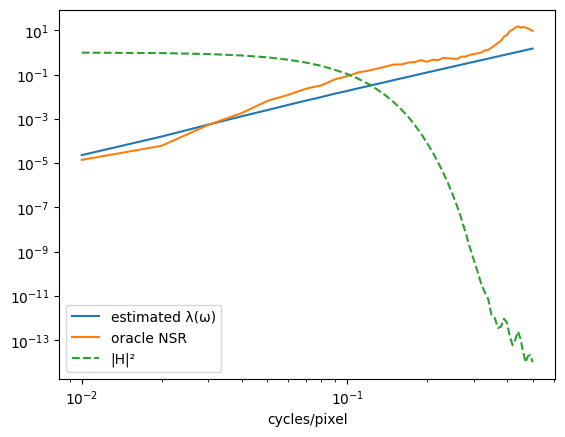

PSNR proposed 29.830181075168895 | oracle 30.30290792333269


In [ ]:
from proposed import *
psf = gaussian_psf(psf_size(2.5), 2.5); sigma = 0.02
y = add_gaussian(blur(x, psf), sigma, np.random.default_rng(0))
xh, info = adaptive_wiener(y, psf, return_info=True)
print(f"sigma true {sigma:.4f} | estimated {np.sqrt(info['sigma2']):.4f} | beta {info['beta']:.2f}")

w = freq_grid(y.shape)
oracle = sigma ** 2 / (np.abs(np.fft.fft2(x)) ** 2 / x.size + 1e-12)
bins = np.linspace(0, 0.5, 51)
radial = lambda M: [np.median(M[(w >= a) & (w < b)]) for a, b in zip(bins[:-1], bins[1:])]
plt.loglog(bins[1:], radial(info['lam']), label='estimated λ(ω)')
plt.loglog(bins[1:], radial(oracle), label='oracle NSR')
plt.loglog(bins[1:], radial(np.abs(psf2otf(psf, y.shape)) ** 2), '--', label='|H|²')
plt.xlabel('cycles/pixel'); plt.legend(); plt.show()
print('PSNR proposed', psnr(x, np.clip(xh, 0, 1)), '| oracle', psnr(x, np.clip(wiener_oracle(y, psf, x, sigma), 0, 1)))

In [ ]:
import yaml
tuned = yaml.safe_load(open(f'{ROOT}/configs/tuned.yaml'))
p_const = psnr(x, np.clip(wiener_const(y, psf, tuned['nsr']), 0, 1))
p_prop  = psnr(x, np.clip(xh, 0, 1))
print(f"wiener_const {p_const:.2f} dB | proposed {p_prop:.2f} dB | gain {p_prop - p_const:+.2f} dB")
print(f"sigma true {sigma:.4f} | estimated {np.sqrt(info['sigma2']):.4f} | beta {info['beta']:.2f}")

wiener_const 29.61 dB | proposed 29.83 dB | gain +0.22 dB
sigma true 0.0200 | estimated 0.0200 | beta 2.67


In [ ]:
import itertools, pandas as pd
from numpy.fft import fft2
from baselines import _apply                     

test_imgs = []                                   
for subset in ['Confocal_BPAE_B', 'TwoPhoton_MICE']:
    gt, _ = fmd_pair(subset, 19)
    for q, crop in enumerate(quadrants(norm_pair(gt)[0])):
        test_imgs.append((f'{subset}_q{q}', crop))

VARIANTS = ['full', 'oracle_sigma', 'oracle_Sx', 'const_lambda']

def lam_variant(y, psf, x, sigma, kind):
    """lambda(w) for one variant. 'full' is exactly adaptive_wiener.
    oracle_sigma: true noise level in place of the estimate. oracle_Sx: true signal spectrum in place of the power-law fit.
    const_lambda: the full lambda(w) collapsed to one number (its geometric mean): same strength, no frequency shaping."""
    w = freq_grid(y.shape); w[0, 0] = w[0, 1]
    s2_hat = estimate_noise_var(y, psf, cfg['eps_band'])
    if kind == 'oracle_Sx':
        return s2_hat / (np.abs(fft2(x)) ** 2 / x.size + 1e-12), s2_hat, np.nan
    s2 = sigma ** 2 if kind == 'oracle_sigma' else s2_hat
    A, beta, _ = fit_signal_psd(y, psf, s2)
    lam = s2 / (A * w ** (-beta))
    if kind == 'const_lambda':
        lam = np.full(y.shape, np.exp(np.mean(np.log(lam))))
    return lam, s2_hat, beta

In [ ]:
rows = []
for (name, x), s_psf, s_n, seed in itertools.product(test_imgs, cfg['psf_sigmas'], cfg['gauss_noise'], cfg['seeds']):
    psf = gaussian_psf(psf_size(s_psf), s_psf)
    y = add_gaussian(blur(x, psf), s_n, np.random.default_rng(seed))
    H = psf2otf(psf, y.shape)
    for kind in VARIANTS:
        lam, s2_hat, beta = lam_variant(y, psf, x, s_n, kind)
        xh = np.clip(_apply(y, H, lam), 0, 1)
        rows.append(dict(img=name, psf=s_psf, noise=s_n, seed=seed, variant=kind, psnr=psnr(x, xh), ssim=ssim(x, xh),
                         sigma_ratio=np.sqrt(s2_hat) / s_n, beta=beta))
abl = pd.DataFrame(rows)
abl.to_csv(f'{ROOT}/results/ablation.csv', index=False)
abl.pivot_table(index=['psf', 'noise'], columns='variant', values='psnr').round(2)

variant    const_lambda   full  oracle_Sx  oracle_sigma
psf noise                                              
1.5 0.005         33.72  34.47      34.79         34.47
    0.010         30.70  33.44      33.79         33.44
    0.020         26.06  32.26      32.63         32.26
    0.050         20.47  30.41      30.80         30.41
2.5 0.005         30.93  31.82      32.04         31.82
    0.010         28.91  31.06      31.30         31.06
    0.020         25.44  30.18      30.44         30.18
    0.050         20.66  28.83      29.11         28.83
4.0 0.005         28.37  29.34      29.49         29.34
    0.010         27.08  28.78      28.95         28.78
    0.020         24.67  28.19      28.36         28.19
    0.050         21.10  27.31      27.50         27.31

In [ ]:
s6 = pd.read_csv(f'{ROOT}/results/synthetic_gauss_test.csv')
s6 = s6[s6.method == 'proposed'].sort_values(['img', 'psf', 'noise', 'seed']).psnr.values
full = abl[abl.variant == 'full'].sort_values(['img', 'psf', 'noise', 'seed'])
print('max |full - S6 proposed| PSNR difference (should be ~0):', np.abs(full.psnr.values - s6).max())
full.groupby(['psf', 'noise'])[['sigma_ratio', 'beta']].agg(['mean', 'std']).round(3)

max |full - S6 proposed| PSNR difference (should be ~0): 7.105427357601002e-15


sigma_ratio          beta       
                 mean    std   mean    std
psf noise                                 
1.5 0.005       0.999  0.001  2.570  0.231
    0.010       0.998  0.001  2.511  0.256
    0.020       0.998  0.001  2.448  0.286
    0.050       0.998  0.001  2.357  0.338
2.5 0.005       1.000  0.002  2.403  0.314
    0.010       0.999  0.002  2.369  0.338
    0.020       0.999  0.002  2.333  0.354
    0.050       0.999  0.002  2.276  0.392
4.0 0.005       1.001  0.002  2.295  0.386
    0.010       0.999  0.001  2.257  0.399
    0.020       0.999  0.001  2.208  0.416
    0.050       0.998  0.001  2.107  0.452